# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [ ]:
import re
import numpy as np
import pandas as pd
import missingno as msno
from matplotlib import pyplot as plt
import seaborn as sns

В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [ ]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename, low_memory=False)

print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)

print("\nСлучайные строки датасета:")
display(df.sample(n=5, random_state=42))

print("\nОбщая информация о датасете:")
df.info()

Saving monster_com_job_sample.csv to monster_com_job_sample.csv
Размер датасета: (22000, 14)

Типы данных:
country            object
country_code       object
date_added         object
has_expired        object
job_board          object
job_description    object
job_title          object
job_type           object
location           object
organization       object
page_url           object
salary             object
sector             object
uniq_id            object
dtype: object

Случайные строки датасета:


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,NaN,No,jobs.monster.com,The QC Lead position requires an understanding...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lea...,NaN,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,NaN,No,jobs.monster.com,JOB DESCRIPTION ...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Su...,NaN,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,NaN,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundati...,NaN,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,NaN,No,jobs.monster.com,GroundskeeperWest Knox Apart need a F/T Ground...,Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",NaN,http://jobview.monster.com/Groundskeeper-Job-K...,NaN,NaN,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,NaN,No,jobs.monster.com,Combined Insurance is seeking Sales Agents to ...,Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Kno...,NaN,NaN,ec59e3f419b851259632b757183d7365



Общая информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   country          22000 non-null  object
 1   country_code     22000 non-null  object
 2   date_added       122 non-null    object
 3   has_expired      22000 non-null  object
 4   job_board        22000 non-null  object
 5   job_description  22000 non-null  object
 6   job_title        22000 non-null  object
 7   job_type         20372 non-null  object
 8   location         22000 non-null  object
 9   organization     15133 non-null  object
 10  page_url         22000 non-null  object
 11  salary           3446 non-null   object
 12  sector           16806 non-null  object
 13  uniq_id          22000 non-null  object
dtypes: object(14)
memory usage: 2.3+ MB


**Задание**

Составьте таблицу, в которой будет содержаться название столбца, тип данных в нем и краткое описание проблем, которые вы заметили при первом взгляде на данные.


| Столбец | Тип данных | Выявленные проблемы |
|---|---|---|
| `country` | object | Все значения одинаковые. |
| `country_code` | object | Все значения одинаковые. |
| `date_added` | object | 99,45% пропусков; даты хранятся как текст. |
| `has_expired` | object | Все значения одинаковые. |
| `job_board` | object | Все значения одинаковые. |
| `job_description` | object | Содержит длинные тексты, которые иногда встречаются в других столбцах. |
| `job_title` | object | В названиях вакансий иногда указывается местоположение. |
| `job_type` | object | 7,40% пропусков; нестандартные форматы записи. |
| `location` | object | Разные форматы адресов; иногда содержится информация не о местоположении. |
| `organization` | object | 31,21% пропусков; иногда встречаются сведения из других столбцов. |
| `page_url` | object | Все ссылки уникальны; очевидных проблем при первичном просмотре не выявлено. |
| `salary` | object | 84,34% пропусков; различные форматы зарплат и периоды оплаты. |
| `sector` | object | 23,61% пропусков; возможны ошибки размещения информации. |
| `uniq_id` | object | Все идентификаторы уникальны; очевидных проблем не выявлено. |

### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью столбчатой диаграммы. Для удобства можно воспользоваться модулем `missingno`.


,Всего ячеек,Пустых ячеек,Доля пропусков (%)
country,22000,0,0.00
country_code,22000,0,0.00
date_added,22000,21878,99.45
has_expired,22000,0,0.00
job_board,22000,0,0.00
job_description,22000,0,0.00
job_title,22000,0,0.00
job_type,22000,1628,7.40
location,22000,0,0.00
organization,22000,6867,31.21


Количество строк с более чем 75% пропусков: 0


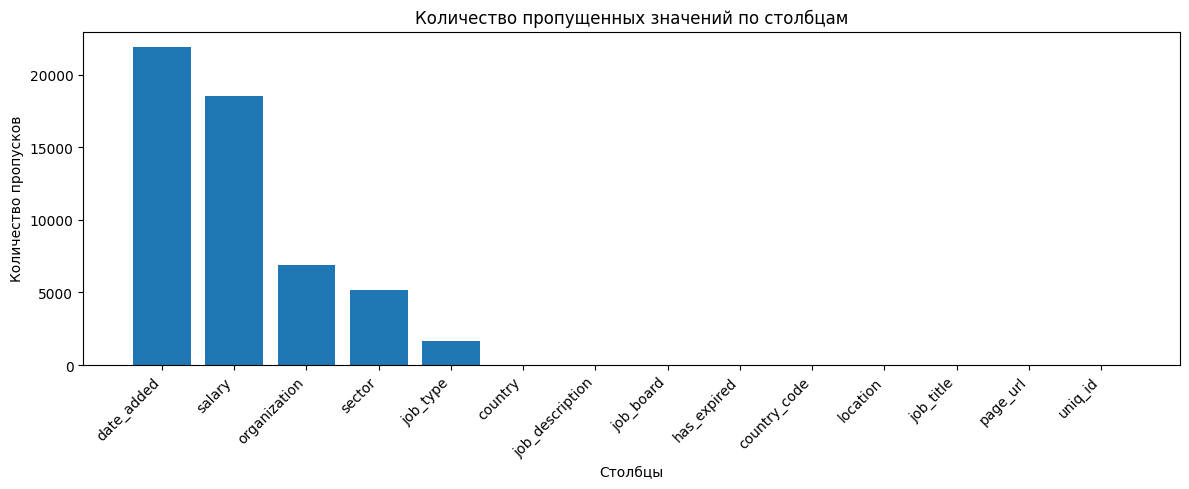

In [ ]:
missing_count = df.isna().sum()

missing_table = pd.DataFrame({
    "Всего ячеек": len(df),
    "Пустых ячеек": missing_count,
    "Доля пропусков (%)": (df.isna().mean() * 100).round(2)
})

display(missing_table)

missing_share = df.isna().mean(axis=1)

rows_over_75 = (missing_share > 0.75).sum()

print("Количество строк с более чем 75% пропусков:", rows_over_75)

missing_sorted = missing_count.sort_values(ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(missing_sorted.index, missing_sorted.values)

plt.title("Количество пропущенных значений по столбцам")
plt.xlabel("Столбцы")
plt.ylabel("Количество пропусков")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Вывод**

 В ходе анализа датасета, содержащего 22 000 записей, были выявлены пропущенные значения в пяти столбцах. Наибольшее количество пропусков обнаружено в `date_added` (99,45%) и `salary` (84,34%). Также пропуски присутствуют в `organization` (31,21%), `sector` (23,61%) и `job_type` (7,40%). В остальных столбцах пропущенные значения отсутствуют. Строк с более чем 75% пропусков не обнаружено. Построенная диаграмма наглядно показывает неравномерное распределение пропусков между столбцами. Таким образом, перед дальнейшим анализом необходимо выбрать подходящие способы обработки отсутствующих значений, чтобы избежать потери полезной информации.

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [ ]:
df_without_missing = df.dropna()

original_rows = len(df)
remaining_rows = len(df_without_missing)

removed_rows = original_rows - remaining_rows
removed_percent = removed_rows / original_rows * 100

print("Исходный размер датасета:", df.shape)
print("Размер после удаления строк с пропусками:", df_without_missing.shape)
print("Количество удалённых строк:", removed_rows)
print(f"Доля удалённых строк: {removed_percent:.2f}%")
print(f"Доля оставшихся строк: {100 - removed_percent:.2f}%")

Исходный размер датасета: (22000, 14)
Размер после удаления строк с пропусками: (5, 14)
Количество удалённых строк: 21995
Доля удалённых строк: 99.98%
Доля оставшихся строк: 0.02%


**Вывод**

после удаления строк с пропущенными значениями из 22 000 записей осталось всего 5 (0,02%). Таким образом, было потеряно 99,98% данных. Это показывает, что полное удаление строк с пропусками плохая затея, поскольку приводит к потере практически всей информации. Поэтому для дальнейшей обработки стоит использовать другие методы работы с пропущенными значениями.

### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [ ]:
unique_counts = df.nunique(dropna=True)

unique_table = pd.DataFrame({
    "Уникальных значений": unique_counts,
    "Пропусков": df.isna().sum()
})

display(unique_table)

constant_columns = unique_counts[unique_counts == 1].index

print("\nСтолбцы с одним уникальным значением:")

for col in constant_columns:
    print(f"{col}: {df[col].dropna().iloc[0]}")

value_sets = {}

for col in df.columns:
    values = df[col].dropna().astype(str).str.strip().str.lower()
    value_sets[col] = set(values[values != ""])

results = []

for i, col1 in enumerate(df.columns):
    for col2 in df.columns[i + 1:]:
        common = value_sets[col1] & value_sets[col2]

        if common:
            results.append({
                "Столбец 1": col1,
                "Столбец 2": col2,
                "Количество совпадений": len(common),
                "Примеры": ", ".join(v[:80] for v in sorted(common)[:5])
            })

if results:
    results_df = pd.DataFrame(results)
    display(results_df.sort_values(
        by="Количество совпадений",
        ascending=False
    ))
else:
    print("Совпадающих значений не обнаружено.")

pairs = [
    ("location", "job_description"),
    ("location", "job_title"),
    ("location", "organization"),
    ("organization", "sector"),
    ("sector", "organization"),
    ("organization", "job_type")
]

for col1, col2 in pairs:
    values = set(
        df[col2].dropna().astype(str).str.strip().str.lower()
    ) - {""}

    mask = (
        df[col1].fillna("").astype(str).str.strip().str.lower().isin(values)
    )

    print(f"\nПроверка: {col1} и {col2}")
    print("Подозрительных строк:", mask.sum())

    display(
        df.loc[mask, [
            "job_title", "location", "organization", "sector", "job_type"
        ]].head(5)
    )

,Уникальных значений,Пропусков
country,1,0
country_code,1,0
date_added,78,21878
has_expired,1,0
job_board,1,0
job_description,18744,0
job_title,18759,0
job_type,39,1628
location,8423,0
organization,738,6867



Столбцы с одним уникальным значением:
country: United States of America
country_code: US
has_expired: No
job_board: jobs.monster.com


,Столбец 1,Столбец 2,Количество совпадений,Примеры
1,job_description,location,849,"""summer walk in wednesdays"" july & august!! - ..."
5,location,organization,126,"a & e network, albany, ny, allentown, pa, appl..."
2,job_title,location,12,"business analyst, field service technician, jo..."
6,organization,sector,2,electrical/electronics engineeringindustrial/m...
0,job_description,job_title,1,please apply only if you are qualified.
4,job_type,organization,1,full time employee
3,job_type,location,1,full time employee



Проверка: location и job_description
Подозрительных строк: 905


,job_title,location,organization,sector,job_type
45,Respiratory Therapist PRN Nights - Kindred Hos...,Respiratory Therapist PRN Nights - Kindred Hos...,Healthcare Services,Medical/Health,"Full Time, Employee"
105,Registered Nurse ICU Full Time Days - Kindred ...,Registered Nurse ICU Full Time Days - Kindred ...,Healthcare Services,Medical/Health,"Full Time, Employee"
115,Experienced Registered Nurse-Critical Care/ICU...,Experienced Registered Nurse-Critical Care/ICU...,Healthcare Services,Medical/Health,"Full Time, Employee"
138,Registered Nurse ICU Full Time Nights - Kindre...,Registered Nurse ICU Full Time Nights - Kindre...,Healthcare Services,Medical/Health,"Full Time, Employee"
188,Assistant Underwriter – Client Services Job in...,"Location: Spokane, WAOverview: Responsible fo...",NaN,Experienced (Non-Manager),NaN



Проверка: location и job_title
Подозрительных строк: 24


... (5 outputs left out)


Проверка: sector и organization
Подозрительных строк: 24


,job_title,location,organization,sector,job_type
795,# Plano Retail Co-Manager Job in Plano,"Plano, TX 75093",Retail,Retail,Full Time Employee
1121,Retail Sales Merchandiser Full Time Job in Dallas,"Dallas, TX",Retail,Retail,Full Time Employee
1810,Field Sales Merchandiser Job in Atlanta,"Atlanta, GA",Retail,Retail,Full Time Employee
1883,Product Support Specialist Job in Tucker,"Tucker, GA","Electronics, Components, and Semiconductor Mfg...",Electrical/Electronics EngineeringIndustrial/M...,Full Time Employee
2629,# Chattanooga Co-Manager Job in Chattanooga,"Chattanooga, TN 37421",Retail,Retail,Full Time Employee



Проверка: organization и job_type
Подозрительных строк: 9


,job_title,location,organization,sector,job_type
4947,Technical Recruiter - Columbus,Full Time Employee,Full Time Employee,NaN,NaN
5350,Paralegal - Immigration Specialist,Full Time Employee,Full Time Employee,NaN,NaN
8727,Client Account Manager - Atlanta,Full Time Employee,Full Time Employee,NaN,NaN
11143,Outdoor Sales High Volume Recruiter Virtual,Full Time Employee,Full Time Employee,NaN,NaN
11504,Onsite Contract Engineer Recruiter - Austin,Full Time Employee,Full Time Employee,NaN,NaN


**Вывод:**

здесь выявлены 4 столбца с одним уникальным значением: `country`, `country_code`, `has_expired` и `job_board`. Эти столбцы не позволяют различать вакансии между собой, но могут использоваться для общего описания датасета. Наибольшее количество уникальных значений обнаружено в `page_url` и `uniq_id` по 22 000.

также обнаружены одинаковые значения в нескольких столбцах. Наибольшее количество совпадений выявлено между job_description и location (849), а также location и organization (126). Это может говорить об ошибках размещения данных. необходимо дополнительно проверить содержимое соответствующих столбцов.

и обнаружены ошибки размещения данных между столбцами. Например, в location встречаются названия и описания вакансий, а в organization сведения о местоположении и виде занятости. Это говорит о нарушении структуры данных. Выявленные ошибки нужно будет учитывать при дальнейшей обработке датасета.

### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [ ]:
print("Уникальность uniq_id:", df["uniq_id"].is_unique)

unique_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) == len(df)
]

print("Столбцы с полностью уникальными значениями:", unique_columns)

columns_to_check = [
    col for col in df.columns
    if col not in unique_columns
]

duplicates = df.duplicated(subset=columns_to_check, keep=False)

print("Количество строк, входящих в группы дубликатов:", duplicates.sum())
print("Количество повторных строк:",
      df.duplicated(subset=columns_to_check).sum())

if duplicates.any():
    display(df.loc[duplicates].head(10))

Уникальность uniq_id: True
Столбцы с полностью уникальными значениями: ['page_url', 'uniq_id']
Количество строк, входящих в группы дубликатов: 2078
Количество повторных строк: 1168


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
17,United States of America,US,NaN,No,jobs.monster.com,We are currently seeking ambitious and persona...,Pest Control Technician – Field Service Rep (E...,"Full Time, Employee","Denver, CO",Accounting and Auditing Services,http://jobview.monster.com/Pest-Control-Techni...,NaN,Installation/Maintenance/Repair,8d8f39de4a07929a92c2e6dd7a72a0af
27,United States of America,US,NaN,No,jobs.monster.com,The Training Department plays a crucial role i...,Traveling Customer Training Professional Job i...,Full Time Employee,"Houston, TX 77040",AllComputer SoftwareComputer/IT Services,http://jobview.monster.com/Traveling-Customer-...,NaN,Customer Support/Client Care,de49594f00f4af8c1e0fbffd85120208
47,United States of America,US,NaN,No,jobs.monster.com,The Project Manager reports directly to the Co...,Project Manager ( Z ) Job in Houston,Full Time Employee,"Houston, TX 77034",NaN,http://jobview.monster.com/Project-Manager-192...,NaN,Business/Strategic Management,ac2da666b68583ed3c3cc4eaee869eb1
56,United States of America,US,NaN,No,jobs.monster.com,DescriptionIf your goal is to begin a fantasti...,CASHIER Job in Houston,Full Time,"Houston, TX",Retail,http://jobview.monster.com/CASHIER-Job-Houston...,NaN,Experienced (Non-Manager),bcf70c41acf97ac8024c0b38c6fcaf87
95,United States of America,US,NaN,No,jobs.monster.com,The Judge Group is looking for a Scrum Master ...,Scrum Master Job in Denver,"Full Time, Employee","Denver, CO",Computer/IT Services,http://jobview.monster.com/Scrum-Master-Job-De...,NaN,IT/Software Development,5091d726fbce4a824fe6a1d49458ad4a
96,United States of America,US,NaN,No,jobs.monster.com,Financial Advisor Northwestern MutualOur finan...,Financial Advisor / Financial Sales Representa...,Full Time Employee,"Houston, TX",Banking,http://jobview.monster.com/Financial-Advisor-F...,NaN,Sales/Retail/Business Development,e52d5e30ecdf97dd64a44f45bfc2032b
114,United States of America,US,NaN,No,jobs.monster.com,Event Promotions: Marketing / Advertising / Pu...,Event Promotions: Marketing / Advertising / Pu...,Full Time Employee,"Houston, TX 77057",RetailAdvertising and PR ServicesBusiness Serv...,http://jobview.monster.com/Event-Promotions-Ma...,NaN,Marketing/Product,4b8d7a4b2f7449a446a423a47fab633c
165,United States of America,US,NaN,No,jobs.monster.com,The Enrollment Agent I (EA I) supports Enrollm...,Enrollment Agent I* (-) Job in Denver,"Full Time, Employee","Denver, CO","Computer Software, Computer/IT Services",http://jobview.monster.com/Enrollment-Agent-I-...,NaN,Customer Support/Client Care,c76459c6a16425dcf473a4ccf5bdee33
212,United States of America,US,NaN,No,jobs.monster.com,Job Description : Want more than just a job? J...,Associate,"Full Time , Employee",Job Description : Want more than just a job? J...,Retail,http://jobview.monster.com/Associate-Visual-Co...,NaN,Experienced (Non-Manager),6d8a7d4329b639d0fd01fdae74ad838b
221,United States of America,US,NaN,No,jobs.monster.com,Combined Insurance is seeking Sales Agents to ...,Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Kno...,NaN,NaN,ec59e3f419b851259632b757183d7365


**Вывод**

при проверке датасета мы обнаружили 2078 строк, входящих в группы дубликатов, из которых 1168 являются повторными записями. Столбцы uniq_id и page_url были исключены из сравнения, потом что они содержат уникальные значения для каждой записи и мешают обнаружить совпадения по остальным данным. Выявленные дубликаты могут искажать результаты анализа, поэтому при дальнейшей обработке нужно будет учесть их наличие.

# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

Распределение форматов location:


,Количество записей
location_format,
Город + Штат + Индекс,11360
Город + Штат,7186
Не определён,2607
Город + Индекс,322
Индекс,254
Штат,230
Штат + Индекс,21
Город,11
Штат + Город + Индекс,5



Количество неопределённых форматов: 2607

Доля распознанных записей: 88.15%


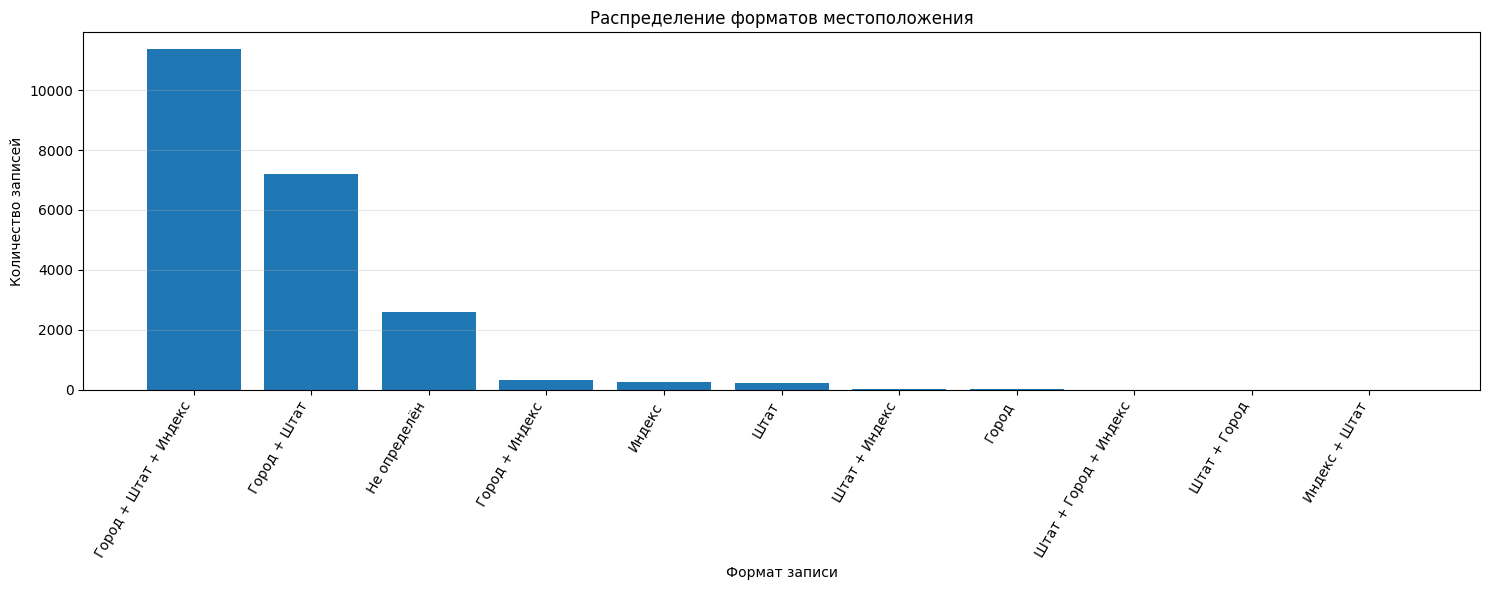


Примеры записей с неопределённым форматом:


,location
2,DePuy Synthes Companies is a member of Johnson...
6,Contact name Tony Zerio
29,"Sr. Process Engineer, Manufacturing"
36,"RF System Technician, Field Service"
38,Bi-Lingual Editorial Strategist
45,Respiratory Therapist PRN Nights - Kindred Hos...
72,"""Statewide"", CO"
73,Quality Engineer
105,Registered Nurse ICU Full Time Days - Kindred ...
115,Experienced Registered Nurse-Critical Care/ICU...


In [ ]:
import re
from itertools import permutations

# крды штатов США
state_codes = """
AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY
LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND
OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY
""".split()

# регулярные выражения для компонентов местоположения
parts = {
    "Город": r"[A-Za-z][A-Za-z .’'\-]{0,59}",
    "Штат": "(?:" + "|".join(state_codes) + ")",
    "Индекс": r"\d{5}(?:-\d{4})?"
}

# разделители
sep = r"(?:\s*[,;/|]\s*|\s+-\s+|\s+)"

# комбинации компонентов
orders = list(permutations(parts, 3))

orders += [
    ("Штат", "Индекс"),
    ("Индекс", "Штат")
]

orders += [
    order for order in permutations(parts, 2)
    if "Город" in order
]

orders += [
    ("Штат",),
    ("Индекс",),
    ("Город",)
]

# регулярные выражения
patterns = [
    (
        order,
        re.compile(
            sep.join(
                f"(?P<{name}>{parts[name]})"
                for name in order
            ),
            re.IGNORECASE
        )
    )
    for order in orders
]

# формат местоположения
def find_format(value):
    if pd.isna(value):
        return None, None

    value = str(value).strip()

    if not value or len(value) > 80 or "\n" in value or ":" in value:
        return None, None

    for order, pattern in patterns:
        match = pattern.fullmatch(value)

        if match:
            city = match.groupdict().get("Город")

            if city and len(city.split()) > 5:
                continue

            return order, city

    return None, None


parsed = df["location"].map(find_format)

known_cities = {
    city.strip(" .,-").casefold()
    for order, city in parsed
    if order and "Город" in order and len(order) > 1
}

# классификация форматов
def classify_format(result):
    order, city = result

    if order is None:
        return "Не определён"

    if order == ("Город",):
        if city.strip(" .,-").casefold() not in known_cities:
            return "Не определён"

    return " + ".join(order)


df["location_format"] = parsed.map(classify_format)

format_counts = df["location_format"].value_counts()

print("Распределение форматов location:")
display(format_counts.to_frame("Количество записей"))

print("\nКоличество неопределённых форматов:",
      (df["location_format"] == "Не определён").sum())

print("\nДоля распознанных записей:",
      f"{(df['location_format'] != 'Не определён').mean() * 100:.2f}%")

# диаграмма
plt.figure(figsize=(15, 6))

plt.bar(format_counts.index, format_counts.values)

plt.title("Распределение форматов местоположения")
plt.xlabel("Формат записи")
plt.ylabel("Количество записей")

plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nПримеры записей с неопределённым форматом:")

display(
    df.loc[
        df["location_format"] == "Не определён",
        ["location"]
    ].head(10)
)

**Вывод**

при анализе столбца `location` с помощью регулярных выражений нам удалось определить форматы 88,15% записей. Наиболее распространёнными оказались «Город + Штат + Индекс» (11 360 записей) и «Город + Штат» (7 186 записей). Для 2607 записей (11,85%) формат определить не удалось. Среди них встречаются названия и описания вакансий вместо местоположения. Таким образом, для дальнейшей обработки нужн будет отдельно рассмотреть нераспознанные значения.

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [ ]:
mask = df["location_format"] == "Не определён"

df_unrecognized = df.loc[mask].copy()
df_recognized = df.loc[~mask].copy()

print("Всего записей:", len(df))
print("Распознанных записей:", len(df_recognized))
print("Нераспознанных записей:", len(df_unrecognized))


pattern_dict = dict(patterns)


# функция извлечения компонентов местоположения
def extract_location(value):
    order, _ = find_format(value)

    result = {
        "city": pd.NA,
        "state_code": pd.NA,
        "postal_code": pd.NA
    }

    if order is None:
        return pd.Series(result)

    match = pattern_dict[order].fullmatch(str(value).strip())

    if match is None:
        return pd.Series(result)

    components = match.groupdict()

    if components.get("Город"):
        result["city"] = components["Город"].strip()

    if components.get("Штат"):
        result["state_code"] = components["Штат"].upper()

    if components.get("Индекс"):
        result["postal_code"] = components["Индекс"]

    return pd.Series(result)


location_parts = df_recognized["location"].apply(extract_location)

df_recognized = df_recognized.join(location_parts)


assert len(df_recognized) + len(df_unrecognized) == len(df)


print("\nПримеры разделённых местоположений:")

display(
    df_recognized[
        ["location", "city", "state_code", "postal_code"]
    ].sample(n=15, random_state=42)
)


print("\nКоличество заполненных значений:")

print("Город:", df_recognized["city"].notna().sum())
print("Код штата:", df_recognized["state_code"].notna().sum())
print("Почтовый индекс:", df_recognized["postal_code"].notna().sum())


print("\nПримеры отложенных записей:")

display(
    df_unrecognized[
        ["job_title", "location"]
    ].head(10)
)

Всего записей: 22000
Распознанных записей: 19393
Нераспознанных записей: 2607

Примеры разделённых местоположений:


,location,city,state_code,postal_code
5095,"Columbus, OH",Columbus,OH,<NA>
17129,"Irving, TX 75039",Irving,TX,75039
359,"Coral Gables, FL 33143",Coral Gables,FL,33143
5936,"New York City, NY 10177",New York City,NY,10177
21256,"Atlanta, GA 30328",Atlanta,GA,30328
3209,"Corpus Christi, TX",Corpus Christi,TX,<NA>
16051,"Cincinnati, OH 45201",Cincinnati,OH,45201
17814,"Dallas, TX 75231",Dallas,TX,75231
15982,"Cincinnati, OH",Cincinnati,OH,<NA>
14402,"Frederick, MD 21701",Frederick,MD,21701



Количество заполненных значений:
Город: 18887
Код штата: 18806
Почтовый индекс: 11963

Примеры отложенных записей:


,job_title,location
2,Johnson & Johnson Family of Companies Job Appl...,DePuy Synthes Companies is a member of Johnson...
6,CyberCoders Job Application for Principal QA E...,Contact name Tony Zerio
29,Sr. Process Engineer,"Sr. Process Engineer, Manufacturing"
36,RF System Technician,"RF System Technician, Field Service"
38,Bi-Lingual Editorial Strategist Job in San Fra...,Bi-Lingual Editorial Strategist
45,Respiratory Therapist PRN Nights - Kindred Hos...,Respiratory Therapist PRN Nights - Kindred Hos...
72,"Formulation Scientist Job in ""Statewide""","""Statewide"", CO"
73,Quality Engineer Job in Durham,Quality Engineer
105,Registered Nurse ICU Full Time Days - Kindred ...,Registered Nurse ICU Full Time Days - Kindred ...
115,Experienced Registered Nurse-Critical Care/ICU...,Experienced Registered Nurse-Critical Care/ICU...


**Вывод**

при  обработке столбца `location` датасет был разделён на 19 393 распознанные и 2607 нераспознанных записей. Для распознанных значений созданы отдельные столбцы города, кода штата и почтового индекса. Удалось извлечь 18 887 значений города, 18 806 кодов штатов и 11 963 почтовых индекса. Все исходные записи сохранены, а нераспознанные данные выделены для дальнейшего анализа.

#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [ ]:
df_recovered = df_unrecognized.copy()

known_city_names = (
    df_recognized["city"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .unique()
)

known_cities = set(known_city_names)

states = "|".join(state_codes)

city_state_pattern = re.compile(
    rf"(?P<city>[A-Za-z][A-Za-z .'\-]{{1,60}}?)"
    rf"\s*,\s*(?P<state>{states})"
    rf"(?:[\s,]+(?P<zip>\d{{5}}(?:-\d{{4}})?))?"
    rf"(?=$|[\s,;.)]|Overview\b|Description\b)",
    re.IGNORECASE
)

state_zip_pattern = re.compile(
    rf"(?<![A-Za-z])(?P<state>{states})"
    rf"[\s,]+(?P<zip>\d{{5}}(?:-\d{{4}})?)\b",
    re.IGNORECASE
)

zip_label_pattern = re.compile(
    r"\b(?:ZIP|Postal Code|Zip Code)\s*[:#-]?\s*"
    r"(?P<zip>\d{5}(?:-\d{4})?)\b",
    re.IGNORECASE
)

state_only_pattern = re.compile(
    rf"(?P<state>{states})",
    re.IGNORECASE
)

zip_only_pattern = re.compile(
    r"\d{5}(?:-\d{4})?"
)


def recover_location(value):

    result = {
        "city": pd.NA,
        "state_code": pd.NA,
        "postal_code": pd.NA
    }

    if pd.isna(value):
        return pd.Series(result)

    text = str(value).strip()

    if not text:
        return pd.Series(result)

    for match in city_state_pattern.finditer(text):

        city = match.group("city").strip(" .,")
        state = match.group("state").upper()
        zipcode = match.group("zip")

        if city.lower() in known_cities:
            result["city"] = city
            result["state_code"] = state

            if zipcode:
                result["postal_code"] = zipcode

            return pd.Series(result)

    match = state_zip_pattern.search(text)

    if match:
        result["state_code"] = match.group("state").upper()
        result["postal_code"] = match.group("zip")

        return pd.Series(result)

    match = state_only_pattern.fullmatch(text)

    if match:
        result["state_code"] = match.group("state").upper()
        return pd.Series(result)

    match = zip_only_pattern.fullmatch(text)

    if match:
        result["postal_code"] = match.group()
        return pd.Series(result)

    match = zip_label_pattern.search(text)

    if match:
        result["postal_code"] = match.group("zip")

    if text.lower() in known_cities:
        result["city"] = text

    return pd.Series(result)


recovered_parts = df_recovered["location"].apply(recover_location)

df_recovered = df_recovered.join(recovered_parts)


components = ["city", "state_code", "postal_code"]

recovered_mask = df_recovered[components].notna().any(axis=1)

recovered_count = recovered_mask.sum()
remaining_count = (~recovered_mask).sum()

print("Всего отложенных записей:", len(df_recovered))
print("Удалось извлечь хотя бы один компонент:", recovered_count)
print("Не удалось извлечь компоненты:", remaining_count)

print("\nКоличество извлечённых значений:")
print("Город:", df_recovered["city"].notna().sum())
print("Код штата:", df_recovered["state_code"].notna().sum())
print("Почтовый индекс:", df_recovered["postal_code"].notna().sum())


print("\nПримеры дополнительно обработанных местоположений:")

display(
    df_recovered.loc[
        recovered_mask,
        ["location", "city", "state_code", "postal_code"]
    ].head(15)
)


print("\nПримеры записей, которые не удалось обработать:")

display(
    df_recovered.loc[
        ~recovered_mask,
        ["job_title", "location", "city", "state_code", "postal_code"]
    ].head(10)
)


df_location_complete = pd.concat(
    [df_recognized, df_recovered]
).sort_index()

assert len(df_location_complete) == len(df)
assert df_location_complete.index.equals(df.index)

print("\nИтоговые результаты обработки location:")
print("Всего записей:", len(df_location_complete))

print("Заполнено значений city:",
      df_location_complete["city"].notna().sum())

print("Заполнено значений state_code:",
      df_location_complete["state_code"].notna().sum())

print("Заполнено значений postal_code:",
      df_location_complete["postal_code"].notna().sum())

Всего отложенных записей: 2607
Удалось извлечь хотя бы один компонент: 581
Не удалось извлечь компоненты: 2026

Количество извлечённых значений:
Город: 354
Код штата: 527
Почтовый индекс: 296

Примеры дополнительно обработанных местоположений:


,location,city,state_code,postal_code
188,"Location: Spokane, WAOverview: Responsible fo...",Spokane,WA,<NA>
304,Contact name Recruiter Phone 503.299.6811 Addr...,<NA>,OR,97239
311,Job Tracking ID: KTTS-17-043 Location: Al...,Alexandria,VA,<NA>
320,Contact name Frias Jobs Phone 702-798-3499 Add...,<NA>,NV,89118
325,Title: Independent Designer Location: San Fran...,San Francisco,CA,<NA>
333,"Location: Mounds View, MN Durati...",Mounds View,MN,<NA>
390,Contact name SHAKER ADVERTISING AGENCY noname ...,<NA>,TN,37919
412,"Contact name Careers, AXA Address Charlotte, N...",<NA>,NC,28202
419,Contact name Stephen Vrondran Phone 2519795013...,<NA>,AL,36561
493,Company Overview:The ADT Corporation (NYSE: AD...,Spokane,WA,<NA>



Примеры записей, которые не удалось обработать:


,job_title,location,city,state_code,postal_code
2,Johnson & Johnson Family of Companies Job Appl...,DePuy Synthes Companies is a member of Johnson...,<NA>,<NA>,<NA>
6,CyberCoders Job Application for Principal QA E...,Contact name Tony Zerio,<NA>,<NA>,<NA>
29,Sr. Process Engineer,"Sr. Process Engineer, Manufacturing",<NA>,<NA>,<NA>
36,RF System Technician,"RF System Technician, Field Service",<NA>,<NA>,<NA>
38,Bi-Lingual Editorial Strategist Job in San Fra...,Bi-Lingual Editorial Strategist,<NA>,<NA>,<NA>
45,Respiratory Therapist PRN Nights - Kindred Hos...,Respiratory Therapist PRN Nights - Kindred Hos...,<NA>,<NA>,<NA>
72,"Formulation Scientist Job in ""Statewide""","""Statewide"", CO",<NA>,<NA>,<NA>
73,Quality Engineer Job in Durham,Quality Engineer,<NA>,<NA>,<NA>
105,Registered Nurse ICU Full Time Days - Kindred ...,Registered Nurse ICU Full Time Days - Kindred ...,<NA>,<NA>,<NA>
115,Experienced Registered Nurse-Critical Care/ICU...,Experienced Registered Nurse-Critical Care/ICU...,<NA>,<NA>,<NA>



Итоговые результаты обработки location:
Всего записей: 22000
Заполнено значений city: 19241
Заполнено значений state_code: 19333
Заполнено значений postal_code: 12259


**Вывод**

после обработки 2607 нераспознанных записей удалось извлечь ещё 354 названия городов, 527 кодов штатов и 296 почтовых индексов. Для поиска использовались регулярные выражения, позволяющие находить местоположения внутри текстовых данных. Часть записей осталась необработанной из-за отсутствия необходимой информации. В результате все 22 000 исходных записей были сохранены, а количество заполненных значений увеличилось.

### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

Распределение форматов salary:


,Количество записей
salary_format,
Пропуск,18557
Диапазон,2389
Не определён,808
Одно значение,145
Up to,101



Доля распознанных записей (без учёта пропусков): 76.53%


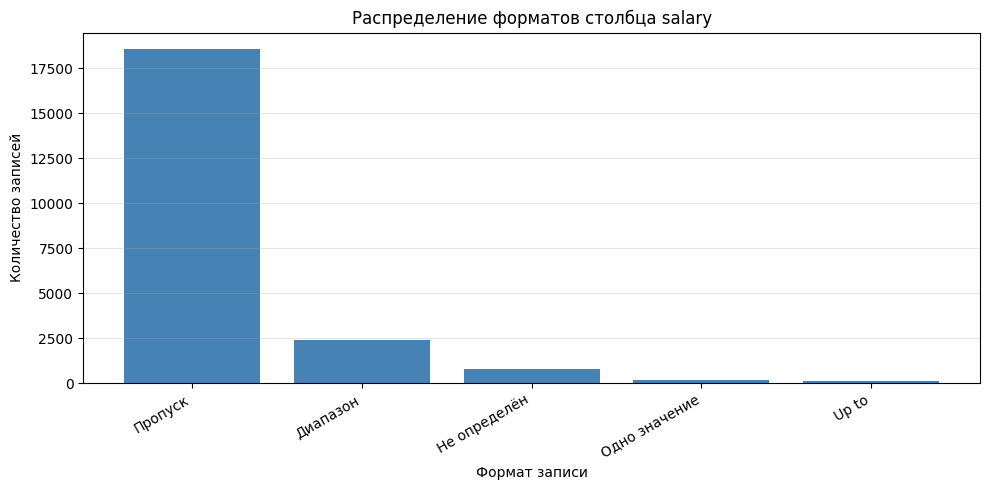


Примеры записей с неопределённым форматом:


,salary
23,Excellent Pay and Incentives
58,"Salary, plus commission"
61,"45,000.00 - 100,000.00 $ /yearBonus, Benefits,..."
64,"40,000.00 - 50,000.00 $ /yearsalary"
68,13.75 - 16.75 $ /hourYear End Bonus
70,To be discussed.
92,"bonus, 401K matching, medical, vacation"
125,DOE
134,"56,000.00 - 64,000.00 $ /yearHighly Competitiv..."
146,"75,000.00 - 130,000.00 $ /yearGenerous Commiss..."


In [ ]:
import re
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

# описание, как выглядит любая сумма денег
money = r"(?:\d{1,3}(?:[ ,]\d{3})+|\d+)(?:\.\d+)?"
# описание, как выглядит знак доллара
dollar = r"\$?"
# описание, как выглядит период
period = r"(?:(?:/|per)\s*(?:hour|year|month|week))?"
# как выглядят разные способы записи зарплат
salary_formats = {
    "Диапазон": re.compile(
        rf"^\s*{dollar}\s*{money}\s*[-–—]\s*{dollar}\s*{money}\s*{dollar}\s*{period}\s*$",
        re.IGNORECASE),
    "Одно значение": re.compile(
        rf"^\s*{dollar}\s*{money}\s*\+?\s*{dollar}\s*{period}\s*$",
        re.IGNORECASE),
    "Up to": re.compile(
        rf"^\s*(?:up\s+to|до)\s*{dollar}\s*{money}\s*{dollar}\s*{period}\s*$",
        re.IGNORECASE),
    "From": re.compile(
        rf"^\s*(?:from|starting\s+at|от)\s*{dollar}\s*{money}\s*\+?\s*{dollar}\s*{period}\s*$",
        re.IGNORECASE),
}

def classify_salary(value):
    if pd.isna(value):
        return "Пропуск"
    # убрать лишние пробелы
    text = str(value).strip()
    if not text:
        return "Пропуск"
    for name, pattern in salary_formats.items():
        if pattern.fullmatch(text):
            return name
    return "Не определён"

# Классификатор ко всему столбцу и количество каждого формата
df["salary_format"] = df["salary"].map(classify_salary)
format_counts = df["salary_format"].value_counts()

#Таблица с количеством записей для каждого формата
print("Распределение форматов salary:")
display(format_counts.to_frame("Количество записей"))

recognized = df["salary_format"].isin(["Диапазон", "Одно значение", "Up to", "From"])
nonempty = df["salary_format"] != "Пропуск"
print("\nДоля распознанных записей (без учёта пропусков):",
      f"{recognized.sum() / nonempty.sum() * 100:.2f}%")

plt.figure(figsize=(10, 5))
plt.bar(format_counts.index, format_counts.values, color="steelblue")
plt.title("Распределение форматов столбца salary")
plt.xlabel("Формат записи")
plt.ylabel("Количество записей")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nПримеры записей с неопределённым форматом:")
display(df.loc[df["salary_format"] == "Не определён", ["salary"]].head(10))

В ходе выполнения задания были проанализированы данные в столбце salary. С помощью регулярных выражений были выделены основные форматы записи заработной платы: "Диапазон", "Одно значение", а также форматы с указанием границ "Up to" и "From". Код классифицировал каждую запись, определил долю распознанных значений и построил столбчатую диаграмму для наглядного отображения частоты встречаемости каждого формата. Также были выведены примеры записей, которые не подошли ни под один шаблон.

Анализ показал, что 84,34% записей в столбце salary пусты. Среди заполненных данных преобладают записи в формате "Диапазон" (2389 записей) и "Одно значение" (145 записей). Благодаря улучшенному регулярному выражению, формат "Up to" теперь распознается корректно (101 запись), а формат "From" в данной выборке не встретился. Доля успешно распознанных записей (без учета пустых строк) составила 76,53%. Оставшиеся 808 записей (формат "Не определён") содержат сложные текстовые конструкции, бонусы, приписки (например, "Excellent Pay and Incentives", "Salary, plus commission"), либо склеенный текст без пробелов. Для дальнейшего анализа эти записи потребуют дополнительной очистки или будут исключены. В целом, написанные регулярные выражения успешно справляются с задачей стандартизации большинства типовых форматов зарплат.

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

Количество заполненных значений:
Минимальная зарплата: 3064
Максимальная зарплата: 2633
Период: 2922


,salary,salary_min,salary_max,salary_period
13,9.00 - 13.00 $ /hour,9.00,13.00,hour
14,"80,000.00 - 95,000.00 $ /year",80000.00,95000.00,year
19,"60,000.00 - 72,000.00 $ /year",60000.00,72000.00,year
23,Excellent Pay and Incentives,NaN,NaN,<NA>
29,"70,000.00 - 100,000.00 $ /year",70000.00,100000.00,year
30,62.00 - 81.00 $ /hour,62.00,81.00,hour
32,"75,000.00 - 100,000.00 $ /year",75000.00,100000.00,year
36,"68,000.00 - 72,000.00 $ /year",68000.00,72000.00,year
41,"58,000.00 - 65,000.00 $ /year",58000.00,65000.00,year
42,Up to $32000.00,32000.00,NaN,<NA>



Средняя и медианная минимальная зарплата по периодам:


,mean,median
salary_period,,
year,62855.209949,60000.00
month,6048.408824,4905.22
week,553.166667,600.00
hour,188.565136,16.00


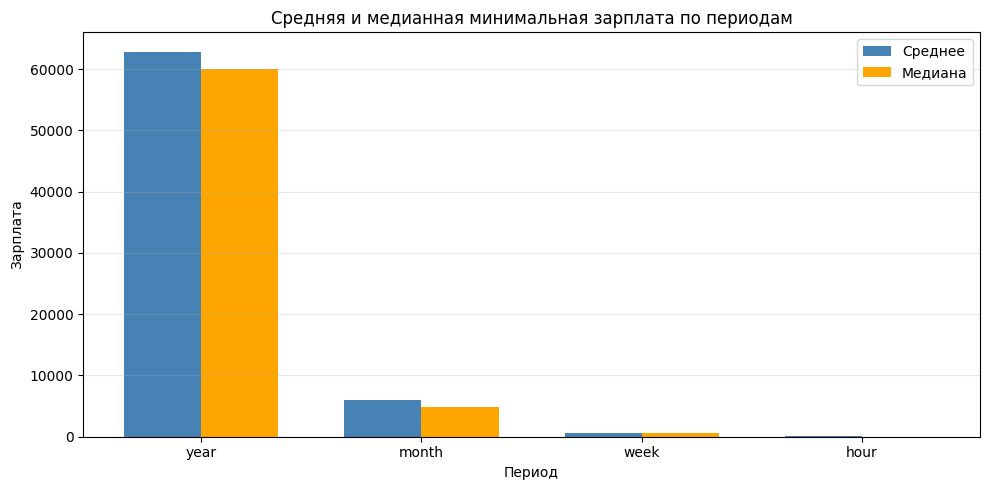

In [ ]:
money_num = r"((?:\d{1,3}(?:[ ,]\d{3})+|\d+)(?:\.\d+)?)"
period_map = {"hour": "hour", "year": "year", "month": "month", "week": "week"}

df = df.drop(columns=["salary_min", "salary_max", "salary_period"], errors="ignore")

def parse_salary(value):
    result = {"salary_min": np.nan, "salary_max": np.nan, "salary_period": pd.NA}
    if pd.isna(value):
        return pd.Series(result)
    text = str(value).strip().lower()
    if not text:
        return pd.Series(result)

    m = re.search(r"(?:/|per)\s*(hour|year|month|week)", text)
    if m:
        result["salary_period"] = period_map[m.group(1)]

    text_clean = re.sub(r"(?:up\s+to|from|starting\s+at|до|от)", " ", text)
    text_clean = re.sub(r"(?:/|per)\s*(?:hour|year|month|week)", " ", text_clean)
    text_clean = text_clean.replace("$", " ").replace("+", " ")

    numbers = re.findall(money_num, text_clean)

    def to_float(s):
        s = s.replace(" ", "").replace(",", "")
        try:
            return float(s)
        except ValueError:
            return np.nan

    nums = [to_float(n) for n in numbers if n.strip()]
    nums = [n for n in nums if not np.isnan(n)]

    if "401k" in text or "401(k)" in text:
        nums = [n for n in nums if n != 401.0]
    nums = [n for n in nums if n != 0.0]

    if len(nums) == 1:
        result["salary_min"] = nums[0]
    elif len(nums) >= 2:
        if re.search(r"[-–—]", text):
            result["salary_min"] = min(nums[0], nums[1])
            result["salary_max"] = max(nums[0], nums[1])
        else:
            result["salary_min"] = nums[0]

    return pd.Series(result)

salary_parts = df["salary"].apply(parse_salary)
df = df.join(salary_parts)

print("Количество заполненных значений:")
print("Минимальная зарплата:", df["salary_min"].notna().sum())
print("Максимальная зарплата:", df["salary_max"].notna().sum())
print("Период:", df["salary_period"].notna().sum())

display(df.loc[df["salary"].notna(), ["salary", "salary_min", "salary_max", "salary_period"]].head(15))

salary_stats = (
    df.dropna(subset=["salary_min", "salary_period"])
      .groupby("salary_period")["salary_min"]
      .agg(["mean", "median"])
      .sort_values("mean", ascending=False)
)
print("\nСредняя и медианная минимальная зарплата по периодам:")
display(salary_stats)

plt.figure(figsize=(10, 5))
x = np.arange(len(salary_stats)); width = 0.35
plt.bar(x - width/2, salary_stats["mean"], width, label="Среднее", color="steelblue")
plt.bar(x + width/2, salary_stats["median"], width, label="Медиана", color="orange")
plt.xticks(x, salary_stats.index)
plt.title("Средняя и медианная минимальная зарплата по периодам")
plt.xlabel("Период"); plt.ylabel("Зарплата")
plt.legend(); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

В ходе выполнения задания исходный текстовый столбец salary был разделен на три новых признака: salary_min, salary_max и salary_period. Из текста были извлечены числовые значения и преобразованы в вещественный тип данных. Если в ячейке была указана только одна сумма, она была записана в минимальную границу, а максимальная оставалась пустой. Дополнительно мы добавили фильтры, чтобы программа не путала текст с зарплатой. Затем был проведен групповой анализ: для каждого периода были вычислены среднее и медианное значения минимальной зарплаты. Результаты визуализированы на столбчатой диаграмме с группировкой.

Алгоритм успешно извлек данные: минимальная зарплата определена для 3064 записей, максимальная - для 2633, период - для 2922 записей. Анализ показал ожидаемую разницу в масштабах: самая высокая годовая зарплата - среднее значение около 62 855, медиана 60 000. Для периода month средняя составляет 6 048, для week - 553, для hour - 188.

На графике заметно, что для периода hour среднее значение превышает медиану (188 против 16.0). Это свидетельствует о наличии выбросов в данных - например, годовые зарплаты, которые из-за отсутствия явного указания периода или сложностей парсинга были отнесены к почасовым. Медиана в данном случае является более устойчивой метрикой и лучше отражает реальную картину (типичная почасовая ставка - около 16 долларов). В целом, разделение зарплаты на числовые признаки и период, а также предварительная очистка от мусора, позволяет в дальнейшем приводить все суммы к единому масштабу (например, к годовой зарплате) для корректного сравнения вакансий.

#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

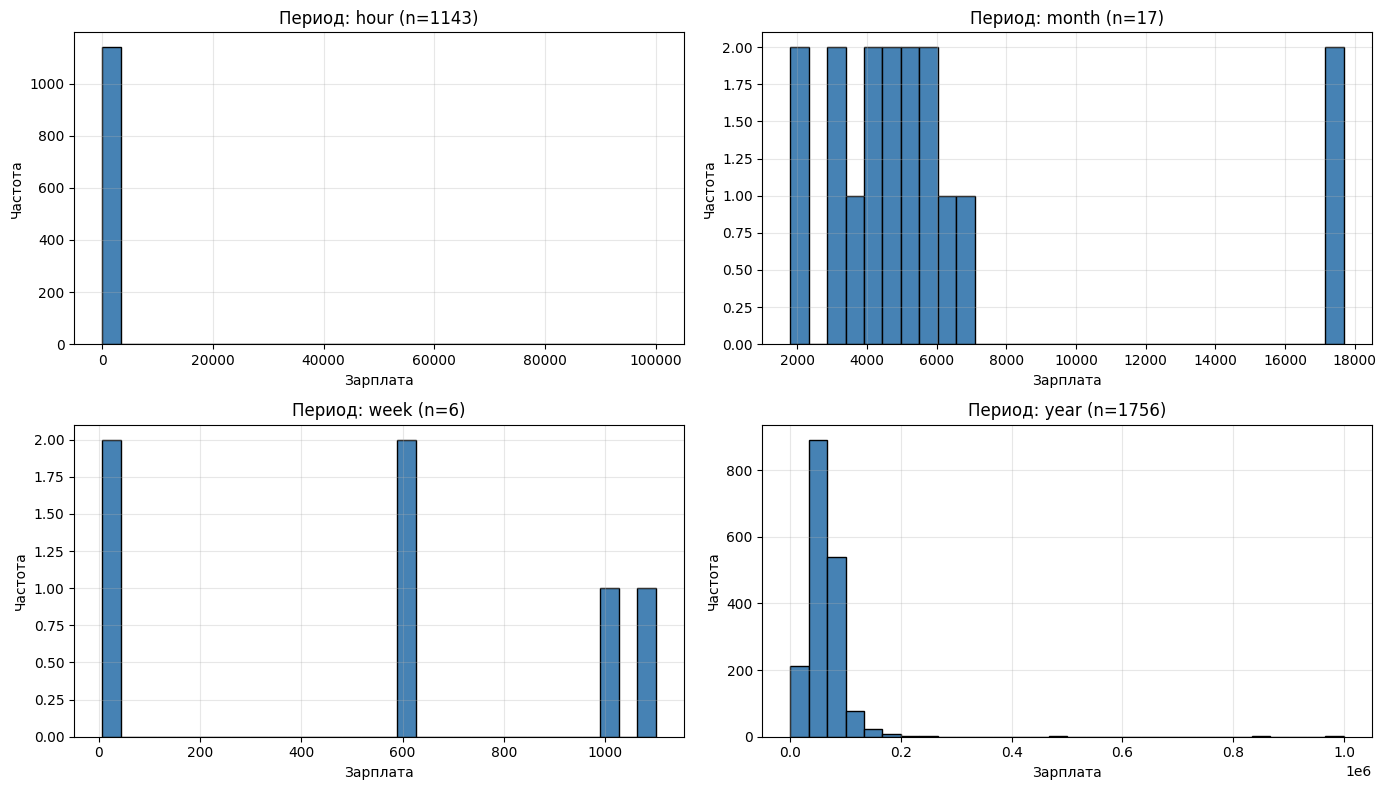

hour: диапазон [7.83; 70.00], усеченное среднее 20.36
month: диапазон [1812.48; 17688.94], усеченное среднее 6313.93
week: диапазон [7.25; 1095.00], усеченное среднее 553.00
year: диапазон [5.40; 160000.00], усеченное среднее 60486.79

Восстановлено периодов: 137
Осталось без периода: 18941


,salary,salary_min,salary_period_recovered
42,Up to $32000.00,32000.0,year
154,Up to $45000.00,45000.0,year
2424,"108,887.00 - 141,555.00",108887.0,year
2630,Up to $18.00,18.0,hour
2639,Up to $13.00,13.0,hour
2651,Up to $18.00,18.0,hour
2655,Up to $14.00,14.0,hour
2669,Up to $18.00,18.0,hour
2717,Up to $15.00,15.0,hour
2792,Up to $30000.00,30000.0,year


In [ ]:
periods = ["hour", "month", "week", "year"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8)); axes = axes.ravel()
for i, p in enumerate(periods):
    subset = df.loc[df["salary_period"] == p, "salary_min"].dropna()
    if len(subset) == 0:
        axes[i].set_visible(False); continue
    axes[i].hist(subset, bins=30, color="steelblue", edgecolor="black")
    axes[i].set_title(f"Период: {p} (n={len(subset)})")
    axes[i].set_xlabel("Зарплата"); axes[i].set_ylabel("Частота")
    axes[i].grid(alpha=0.3)
plt.tight_layout(); plt.show()

ranges = {}
for p in periods:
    subset = df.loc[df["salary_period"] == p, "salary_min"].dropna()
    if len(subset) == 0:
        continue
    q1, q99 = subset.quantile([0.01, 0.99])
    trimmed_mean = subset[(subset >= q1) & (subset <= q99)].mean()
    ranges[p] = (q1, q99, trimmed_mean)
    print(f"{p}: диапазон [{q1:.2f}; {q99:.2f}], усеченное среднее {trimmed_mean:.2f}")

def recover_period(row):
    if pd.notna(row["salary_period"]) or pd.isna(row["salary_min"]):
        return row["salary_period"]

    text = str(row["salary"]).lower()
    if any(word in text for word in ["bonus", "hiring", "sign-on", "sign on"]):
        return pd.NA

    value = row["salary_min"]
    in_range = [p for p, (lo, hi, _) in ranges.items() if lo <= value <= hi]
    if len(in_range) == 1:
        return in_range[0]
    if len(in_range) > 1:
        dists = sorted((abs(value - ranges[p][2]), p) for p in in_range)
        if len(dists) == 1 or dists[0][0] < dists[1][0]:
            return dists[0][1]
        return pd.NA
    dists = sorted((abs(value - ranges[p][2]), p) for p in ranges)
    if len(dists) == 1 or dists[0][0] < dists[1][0] * 0.5:
        return dists[0][1]
    return pd.NA

df["salary_period_recovered"] = df.apply(recover_period, axis=1)

recovered = df["salary_period"].isna() & df["salary_period_recovered"].notna()
print("\nВосстановлено периодов:", recovered.sum())
print("Осталось без периода:",
      (df["salary_period"].isna() & df["salary_period_recovered"].isna()).sum())
display(df.loc[recovered, ["salary", "salary_min", "salary_period_recovered"]].head(10))

В ходе выполнения задания на основе данных из предыдущего шага для каждого периода были рассчитаны диапазоны изменения минимальных зарплат, а также построены гистограммы для визуальной оценки распределения. Для борьбы с выбросами (аномально большими или маленькими суммами) границы диапазонов определялись не по минимуму и максимуму, а по 1-му и 99-му процентилям. Аналогично для расчета среднего использовалось "усеченное" среднее (исключая крайние 1% значений). После этого была написана функция recover_period, которая для записей с известной суммой, но отсутствующим периодом, сопоставляла эту сумму с рассчитанными диапазонами. Если сумма попадала в диапазон одного из периодов, ей присваивался этот период. В спорных случаях (когда сумма была близка к нескольким периодам) значение оставляли пустым.

Дополнительно был добавлен фильтр, который исключает из автоматического восстановления единовременные бонусы (слова "bonus", "hiring", "sign-on"), так как они не являются регулярной оплатой труда.

В результате работы алгоритма удалось предположительно восстановить периоды заработной платы для 137 записей на основе статистического анализа распределений. Например, крупная сумма 32000.0 была отнесена к году (year), а небольшие суммы (18.0, 14.0) - к часу (hour). Записи с бонусами (например, "$300 Hiring Bonus") больше не определяются как зарплата за период, что повысило точность. Оставшиеся без периода записи (около 18 941) - это в основном пустые значения или текстовые описания (вроде "Salary, plus commission"), где нет конкретных цифр.

Использование перцентилей и фильтрация бонусов позволили сделать диапазоны устойчивыми к выбросам и избежать ложных срабатываний. Мы убедились, что очистка данных на предыдущих этапах напрямую влияет на качество работы последующих алгоритмов. Теперь данные о зарплатах приведены к единому виду и готовы для дальнейшего анализа.

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

Уникальные значения job_type (до нормализации):


,Количество
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
NaN,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329



Распределение форматов job_type:


,Количество
job_type_format,
Полнота + Тип,12888
Только полнота,7142
Пропуск,1628
Только тип,341
Не определён,1


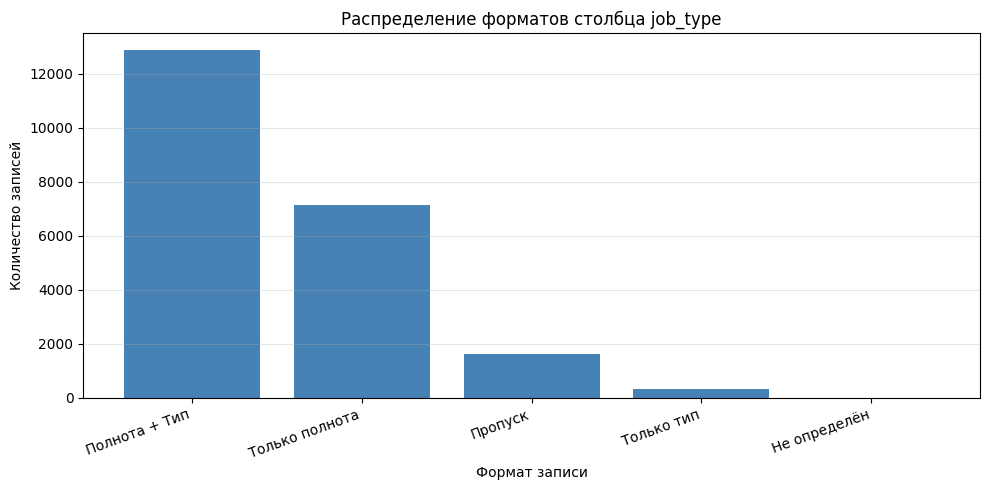

In [ ]:
print("Уникальные значения job_type (до нормализации):")
display(df["job_type"].value_counts(dropna=False).to_frame("Количество"))

def job_type_format(value):
    if pd.isna(value):
        return "Пропуск"
    text = str(value).strip().lower()
    if not text:
        return "Пропуск"
    has_fullness = bool(re.search(r"full\s*time|part\s*time|per\s*diem", text))
    has_type = bool(re.search(r"employee|intern|contract|temporary|temp", text))
    if has_fullness and has_type:
        return "Полнота + Тип"
    if has_fullness:
        return "Только полнота"
    if has_type:
        return "Только тип"
    return "Не определён"

df["job_type_format"] = df["job_type"].map(job_type_format)
format_counts = df["job_type_format"].value_counts()

print("\nРаспределение форматов job_type:")
display(format_counts.to_frame("Количество"))

plt.figure(figsize=(10, 5))
plt.bar(format_counts.index, format_counts.values, color="steelblue")
plt.title("Распределение форматов столбца job_type")
plt.xlabel("Формат записи"); plt.ylabel("Количество записей")
plt.xticks(rotation=20, ha="right"); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

В ходе анализа столбца job_type были выведены все уникальные значения и подсчитана частота их встречаемости. С помощью регулярных выражений была проведена классификация записей: скрипт проверял наличие информации о полноте занятости (Full Time, Part Time, Per Diem) и о типе занятости (Employee, Intern, Contract/Temporary). На основе этого все записи были разделены на четыре категории: содержащие обе части, содержащие только полноту, содержащие только тип, а также пустые значения (пропуски) и неопределённые записи. Результаты визуализированы на столбчатой диаграмме.

Анализ показал, что исходный столбец job_type содержит сильный "разнобой" в форматировании: одинаковые по смыслу значения записаны по-разному (с запятыми, без запятых, через слэш, с разным регистром, а также с лишними словами вроде "Job Type"). Большая часть записей (12 888) содержит обе характеристики - полноту и тип занятости. Ещё 7 142 записи содержат только информацию о полноте (например, просто "Full Time"). Пропуски составляют 1 628 записей. Категория "Только тип" встречается редко (341 запись), а неопределённых записей всего одна (скорее всего, это слово "Exempt"). Наличие такого количества вариаций подтверждает необходимость проведения нормализации (приведения к единому виду) и последующего разделения этого столбца на два отдельных признака.


Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [ ]:
def normalize_job_type(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).strip().lower()
    text = re.sub(r"\s+", " ", text).replace(",", " ").replace("/", " ")
    text = re.sub(r"\s+", " ", text).strip()

    if re.search(r"full\s*time", text):
        fullness = "Full Time"
    elif re.search(r"part\s*time", text):
        fullness = "Part Time"
    elif re.search(r"per\s*diem", text):
        fullness = "Per Diem"
    else:
        fullness = None

    if re.search(r"intern", text):
        jtype = "Intern"
    elif re.search(r"contract|temporary|temp\b", text):
        jtype = "Contract"
    elif re.search(r"employee", text):
        jtype = "Employee"
    else:
        jtype = None

    parts = [p for p in [fullness, jtype] if p]
    return ", ".join(parts) if parts else pd.NA

df["job_type_clean"] = df["job_type"].map(normalize_job_type)

print("Уникальные значения после нормализации:")
display(df["job_type_clean"].value_counts(dropna=False).to_frame("Количество"))

Уникальные значения после нормализации:


,Количество
job_type_clean,
"Full Time, Employee",10538
Full Time,6773
"Full Time, Contract",1654
<NA>,1629
"Part Time, Employee",586
Part Time,347
Contract,193
Employee,148
"Part Time, Contract",57


В ходе нормализации текстовые значения были очищены от лишних символов (запятых, слэшей, лишних пробелов). Благодаря регулярным выражениям, разрозненные варианты написания (например, "Full Time Employee", "Full Time, Employee" и "full time employee") были приведены к единому стандарту: "Полнота, Тип". До нормализации в столбце насчитывалось несколько десятков уникальных строк, а после очистки осталось всего 13 логических комбинаций. Наиболее частыми стали "Full Time, Employee" (10 538) и "Full Time" (6 773). Это позволило избавиться от дублирующихся по смыслу категорий и подготовить данные для финального разделения на два отдельных признака.

Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

Полнота занятости:


,Количество
employment_fullness,
Full Time,20940
Part Time,993
Per Diem,67



Тип занятости:


,Количество
employment_type,
Employee,20084
Contract,1908
Intern,8



Кросс-таблица:


employment_type,Contract,Employee,Intern
employment_fullness,,,
Full Time,1847,19088,5
Part Time,57,933,3
Per Diem,4,63,0


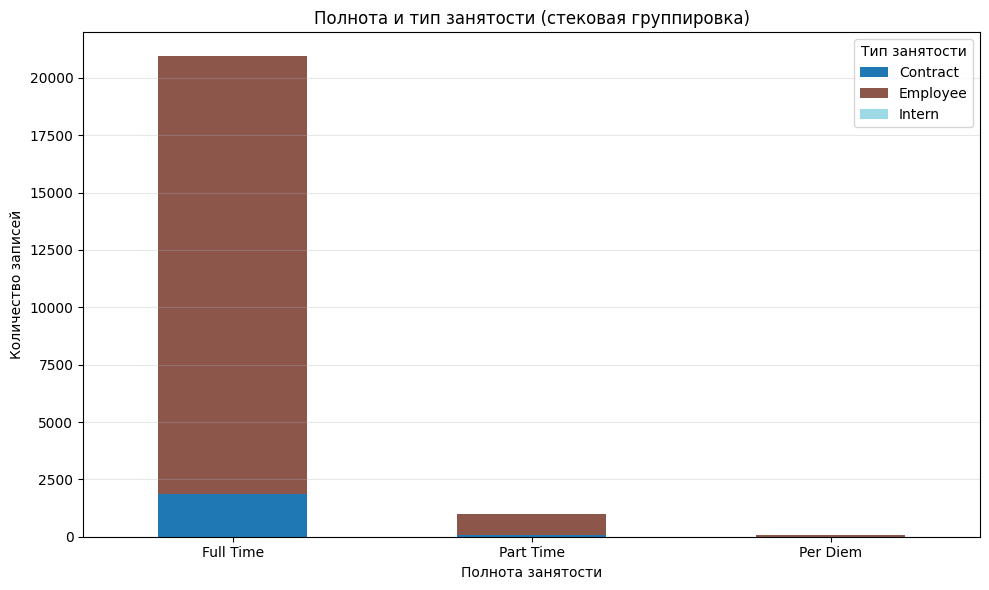

In [ ]:
fullness_pattern = re.compile(r"(full\s*time|part\s*time|per\s*diem)", re.IGNORECASE)
type_pattern = re.compile(r"(employee|intern|contract|temporary|temp)", re.IGNORECASE)

df = df.drop(columns=["employment_fullness", "employment_type"], errors="ignore")

def split_job_type(value):
    if pd.isna(value):
        return pd.Series({"employment_fullness": "Full Time", "employment_type": "Employee"})
    text = str(value).strip().lower()
    text = re.sub(r"\s+", " ", text).replace(",", " ").replace("/", " ")

    fullness = pd.NA
    m = fullness_pattern.search(text)
    if m:
        f = re.sub(r"\s+", " ", m.group(1).lower())
        fullness = {"full time": "Full Time", "part time": "Part Time", "per diem": "Per Diem"}[f]

    jtype = pd.NA
    m = type_pattern.search(text)
    if m:
        t = m.group(1).lower()
        if t == "intern":
            jtype = "Intern"
        elif t in ("contract", "temporary", "temp"):
            jtype = "Contract"
        else:
            jtype = "Employee"

    if pd.isna(fullness):
        fullness = "Full Time"
    if pd.isna(jtype):
        jtype = "Employee"
    return pd.Series({"employment_fullness": fullness, "employment_type": jtype})

split = df["job_type"].apply(split_job_type)
df = df.join(split)

print("Полнота занятости:")
display(df["employment_fullness"].value_counts().to_frame("Количество"))
print("\nТип занятости:")
display(df["employment_type"].value_counts().to_frame("Количество"))

cross = pd.crosstab(df["employment_fullness"], df["employment_type"])
print("\nКросс-таблица:")
display(cross)

cross.plot(kind="bar", stacked=True, figsize=(10, 6), colormap="tab20")
plt.title("Полнота и тип занятости (стековая группировка)")
plt.xlabel("Полнота занятости"); plt.ylabel("Количество записей")
plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.3)
plt.legend(title="Тип занятости"); plt.tight_layout(); plt.show()

В ходе выполнения задания с помощью регулярных выражений исходный столбец job_type был успешно разделён на два независимых признака: employment_fullness (полнота занятости) и employment_type (тип занятости). В соответствии с условием, для записей с отсутствующими данными были установлены значения по умолчанию - "Full Time" и "Employee".

Анализ кросс-таблицы и стековой диаграммы показал, что подавляющее большинство вакансий в датасете (20 940 из 22 000) предполагают полную занятость (Full Time). Среди них абсолютное большинство составляют позиции с типом "Employee" (19 088 записей). Доли частичной занятости (Part Time - 993 записи), временной работы (Contract - 1 908 записей) и стажировок (Intern - всего 8 записей) крайне малы. Разделение на два столбца позволило избавиться от смешанных текстовых форматов, заполнить пропуски дефолтными значениями и сделать данные пригодными для точной фильтрации и статистического анализа.

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.